# 7. Does a sliding window help?

Notebook 4 scores every ten-minute reading on its own. That is the weakness we wrote
down at the time: one odd reading counts exactly as much as a full hour of them,
although only the second is worth sending a technician out for.

Notebook 6 then showed why it matters. At the chosen threshold the detector finds
F1 and F2 only *after* they have started, and gives real advance warning on F3 alone.

The fix is the sliding window from lecture block 1: instead of the sensor readings at
one instant, use their average over the last hour. A single strange reading is then
diluted by the five around it, while a sustained change comes through at full
strength.

This notebook is a comparison, not a replacement. Notebook 4 keeps its scores; this
one produces a second set, and we check whether they are any better.

In [1]:
import sys
import zipfile

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KernelDensity

sys.path.append('..')
from util import evaluation

SENSORS = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs',
           'Oil_temperature', 'Motor_current']

FAILURES = [
    ('2020-04-18', '2020-04-18 23:59'),
    ('2020-05-29', '2020-05-30 23:59'),
    ('2020-06-05', '2020-06-07 23:59'),
    ('2020-07-15', '2020-07-15 23:59'),
]
LABELS = ['F1', 'F2', 'F3', 'F4']

## The same data as notebook 4

In [2]:
with zipfile.ZipFile('../data/metropt3.zip') as z:
    name = [n for n in z.namelist() if n.endswith('.csv')][0]
    with z.open(name) as f:
        raw = pd.read_csv(f)

raw['timestamp'] = pd.to_datetime(raw['timestamp'])
data = raw.sort_values('timestamp').set_index('timestamp')[SENSORS]
data = data.resample('10min').mean().dropna()

print(f'{len(data):,} rows')

25,521 rows


## The window

One line: replace each reading by the average of the last hour. We use `'1h'` rather
than a count of rows because the series has gaps, and a time-based window stays an
hour wide across them.

An hour is six readings. Long enough to drown out a single spike, short enough that
a leak developing over an afternoon still shows up well before it is over.

In [3]:
windowed = data.rolling('1h').mean().dropna()

print(f'{len(windowed):,} rows after windowing')

25,521 rows after windowing


## The same detector, twice

Everything else is identical to notebook 4, so any difference comes from the window
and nothing else. Same training period, same scaler, same bandwidth, same 5000-row
sample.

In [4]:
BANDWIDTH = 0.5
rng = np.random.default_rng(0)


def kde_scores(frame):
    '''Notebook 4's detector, applied to whichever frame we pass in.'''
    train = frame.loc[:'2020-03-31']

    scaler = StandardScaler().fit(train)
    X_train = scaler.transform(train)
    X_all = scaler.transform(frame)

    sample = rng.choice(len(X_train), size=5000, replace=False)
    kde = KernelDensity(bandwidth=BANDWIDTH).fit(X_train[sample])

    return pd.Series(-kde.score_samples(X_all), index=frame.index)


plain = kde_scores(data)
smoothed = kde_scores(windowed)

print('both detectors fitted')

both detectors fitted


## Comparing them fairly

A detector is easy to make look good by letting it cry wolf more often, so comparing
them at their own thresholds would prove nothing. Instead we give both the **same
false alarm budget** and ask which one buys more warning with it.

Notebook 6 settled on 22 false alarms over the evaluation period, so that is the
budget. For each detector we find the threshold that produces as close to 22 as we
can get, and compare what we get for the money.

We evaluate from April onwards, as notebook 6 does, because February and March are
what the model was trained on.

In [5]:
EVAL_FROM = '2020-04-01'
BUDGET = 22


def threshold_for_budget(scores, budget=BUDGET):
    '''Lowest threshold whose false alarm count is within budget.'''
    period = scores.loc[EVAL_FROM:]
    for t in np.percentile(period, np.arange(90, 100, 0.05)):
        if evaluation.evaluate(period, FAILURES, t)['false_alarms'] <= budget:
            return t
    return period.max()


results = {}
for name, scores in [('one reading', plain), ('one-hour mean', smoothed)]:
    t = threshold_for_budget(scores)
    r = evaluation.evaluate(scores.loc[EVAL_FROM:], FAILURES, t)
    results[name] = {'threshold': round(t, 1),
                     'detected': r['detected'],
                     'false alarms': r['false_alarms'],
                     **{f'{lab} warning (h)': round(v.total_seconds() / 3600, 1)
                        if pd.notna(v) else np.nan
                        for lab, v in zip(LABELS, r['lead_times'])}}

pd.DataFrame(results).T

,threshold,detected,false alarms,F1 warning (h),F2 warning (h),F3 warning (h),F4 warning (h)
one reading,61.7,3.0,20.0,-0.3,-23.3,37.8,NaN
one-hour mean,39.5,4.0,21.0,-0.5,-23.7,37.3,33.3


## The two scores side by side

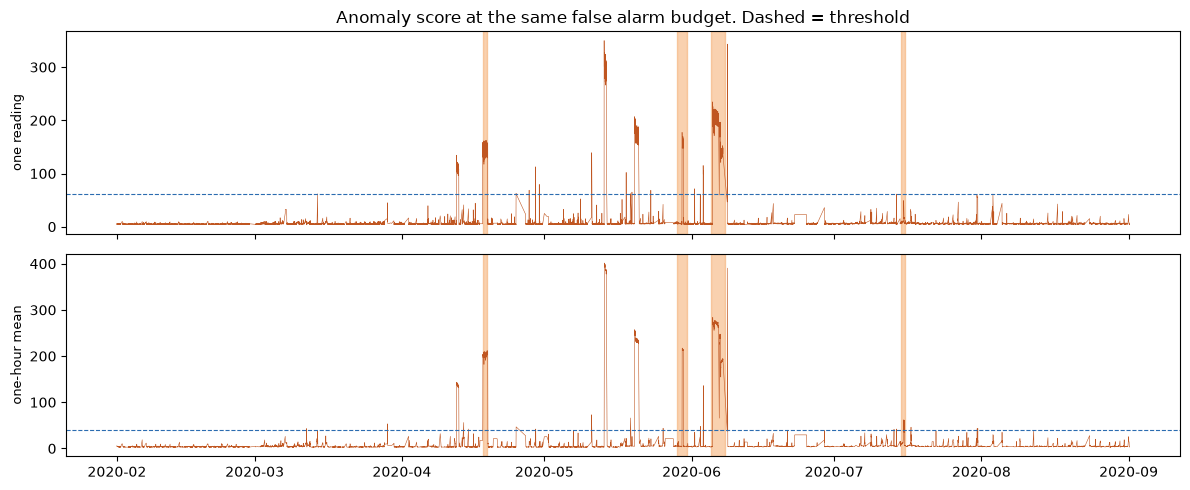

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

for ax, (name, scores) in zip(axes, [('one reading', plain),
                                     ('one-hour mean', smoothed)]):
    ax.plot(scores.index, scores, lw=0.4, color='#c05621')
    ax.axhline(results[name]['threshold'], color='#2b6cb0', lw=0.8, ls='--')
    ax.set_ylabel(name, fontsize=9)
    for start, end in FAILURES:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end),
                   color='sandybrown', alpha=0.5)

axes[0].set_title('Anomaly score at the same false alarm budget. Dashed = threshold')
plt.tight_layout()

## Saving

Notebook 6 can pick this up and rerun its cost analysis against it.

In [7]:
smoothed.rename('score').to_csv('../results/metropt_scores_1h.csv')

print(f'saved {len(smoothed):,} scores to ../results/metropt_scores_1h.csv')

saved 25,521 scores to ../results/metropt_scores_1h.csv


## What we found: no, and that is the interesting part

At a matched budget of about twenty false alarms, the one-hour mean changes the
warning times by less than half an hour on every failure that both detectors find:

| | one reading | one-hour mean |
|---|---|---|
| F1 | 0.3 h late | 0.5 h late |
| F2 | 23.3 h late | 23.7 h late |
| F3 | 37.8 h early | 37.3 h early |
| F4 | not found | 33.3 h early |

The window does pick up F4, but notebook 6 already showed that a detection of F4 is
what you would expect by chance: with alarms at this rate, a random three-day window
catches one about four times in ten. We should not claim it as a win.

So the window buys nothing, and **we keep notebook 4's simpler detector.**

The reason this is worth a slide rather than a deleted branch: it tells us *why* the
detector is late on F1 and F2. If the lateness had been caused by noisy single
readings, averaging six of them would have fixed it. It did not. So the lateness is
not a smoothing problem — the sensors genuinely carry no sign of F1 and F2 before
they begin. No amount of filtering recovers information that is not there.

That is a statement about the machine and the instrumentation, not about our method,
and it is a much better answer to "why does your detector only warn you about one
failure out of four" than a shrug.